In [2]:
%matplotlib inline

# Imports

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sqlite3
import sys
from io import StringIO

# Config

In [4]:
data_dir = Path("../data/260801_135508/")

# Data

In [76]:
type_dict = {"shader_pipeline": str, "ninstances": int, "frame_number": int}
raw_data_dfs = []
for shaderpipeline_dir in data_dir.iterdir():
    shaderpipeline_str = str(shaderpipeline_dir).split("/")[-1]
    print(shaderpipeline_str)
    for ninstance_dir in shaderpipeline_dir.iterdir():
        ninstance_str = str(ninstance_dir).split("/")[-1][1:]
        # print(ninstance_str)
        gpu_frametime_filepath = ninstance_dir / "BASE/FRAME.xls"
        app_data_filepath = ninstance_dir / "app_metrics.csv"
        app_data_with_gpu_filepath = ninstance_dir / "app_metrics_with_gpu.csv"
        
        gpu_frametime_df = pd.read_csv(gpu_frametime_filepath, sep="\t", header=None).T.drop(0).rename(columns={0: "gpu_frame_time_ms"})
        gpu_frametime_df["shader_pipeline"] = shaderpipeline_str
        gpu_frametime_df["ninstances"] = int(ninstance_str)
        gpu_frametime_df = (
            gpu_frametime_df
                .astype({"gpu_frame_time_ms": float, "ninstances": int})
                .reset_index(names=["frame_number"])
                
        )
        gpu_frametime_df["frame_number"] -= 1
        gpu_frametime_df = (
            gpu_frametime_df
                .astype(type_dict)
                .set_index(["shader_pipeline", "ninstances", "frame_number"])
        )
            

        # csv data malformed with trailing , in data and not header column
        with open(app_data_filepath) as f:
            app_data_as_string = "".join(
                line.rstrip("\n").rstrip(",") + "\n"
                for line in f
            )
        app_data_df = (
            pd.read_csv(StringIO(app_data_as_string))
                .dropna(how="any")
                .astype(type_dict)
                .set_index(["shader_pipeline", "ninstances", "frame_number"])
        )

        app_data_with_gpu_df = (
            pd.read_csv(app_data_with_gpu_filepath)
                .dropna(how="any")
                .drop(columns=["frame_time"])
                .astype(type_dict)
                .set_index(["shader_pipeline", "ninstances", "frame_number"])
        )

        raw_data_df = (
            pd.concat([gpu_frametime_df, app_data_df, app_data_with_gpu_df], axis=1, join="inner")
        )
        raw_data_dfs.append(raw_data_df)
        
data_df = (
    pd.concat(raw_data_dfs)
        .round(3)
        .reset_index()
)

asteroidInstancedVertex
asteroidInstancedVertexCompute
asteroidMesh
asteroidMeshCompute
asteroidMeshDXExample


In [77]:
data_df.head()

,shader_pipeline,ninstances,frame_number,gpu_frame_time_ms,frame_time,vram_used
0,asteroidInstancedVertex,10,0,0.710,2949.810,2.236
1,asteroidInstancedVertex,10,1,0.766,6.319,2.190
2,asteroidInstancedVertex,10,2,0.369,0.715,2.190
3,asteroidInstancedVertex,10,3,0.295,0.720,2.190
4,asteroidInstancedVertex,10,4,0.785,0.757,2.190


In [80]:
# instanced vertex missing an ninstances as didn't run
data_df.loc[len(data_df)] = ["asteroidInstancedVertex", 10_000_000, 0, np.nan, np.nan, np.nan]

# Analyse

In [52]:
data_df.describe()

,ninstances,frame_number,gpu_frame_time_ms,frame_time,frame_time,vram_used
count,2.040000e+03,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000
mean,1.339869e+06,29.500000,78.820783,146.303132,117.938040,4.349428
std,3.181660e+06,17.322348,241.261581,568.768069,405.512279,2.949808
min,1.000000e+01,0.000000,0.110000,0.248000,9.847000,2.190000
25%,1.000000e+02,14.750000,0.344000,0.344000,10.474750,2.191000
50%,1.000000e+04,29.500000,0.711500,0.866500,10.810000,2.207000
75%,1.000000e+06,44.250000,21.004250,22.046250,23.659000,5.172000
max,1.000000e+07,59.000000,1452.110000,7614.460000,5998.590000,9.786000


In [82]:
frame_stats = (
    data_df
        .drop(columns=["frame_number"])
        .groupby(["shader_pipeline", "ninstances"])
        .agg(["mean", lambda s: s.std() * 2])\
        .rename(columns={"<lambda_0>": "2_sigma"})
        .round(2)
        .reset_index()
)

<Axes: ylabel='vram_used'>

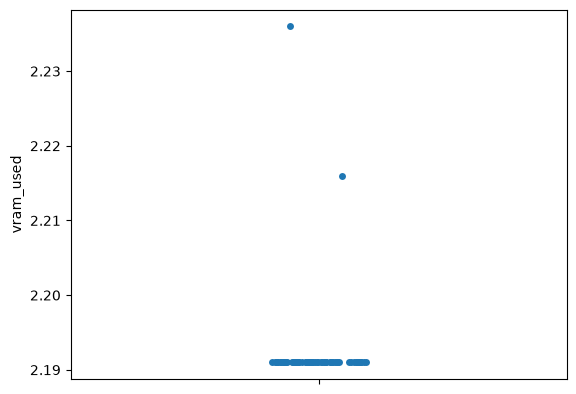

In [99]:
sns.stripplot(data_df[["shader_pipeline", "ninstances", "vram_used"]][(data_df["shader_pipeline"]=="asteroidMeshDXExample") & (data_df["ninstances"]==1_000_000)]["vram_used"])

In [83]:
frame_stats.head()

shader_pipeline ninstances gpu_frame_time_ms         frame_time  \
                                                   mean 2_sigma       mean   
0  asteroidInstancedVertex         10              0.34    0.31      49.61   
1  asteroidInstancedVertex        100              0.49    0.31      47.98   
2  asteroidInstancedVertex       1000              1.81    0.54      49.21   
3  asteroidInstancedVertex      10000             13.85    0.72      61.43   
4  asteroidInstancedVertex     100000            136.09    2.01     182.64   

          vram_used          
  2_sigma      mean 2_sigma  
0  761.52      2.19    0.01  
1  733.88      2.19    0.01  
2  732.54      2.19    0.01  
3  734.06      2.19    0.01  
4  709.42      2.19    0.02

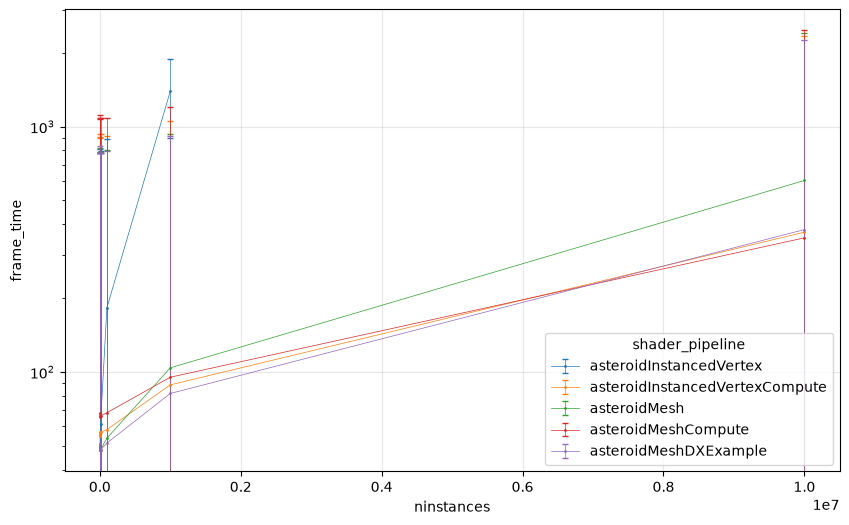

In [85]:
column = "frame_time"
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_yscale("log")
for shader, grp in frame_stats.groupby("shader_pipeline"):
    x = grp["ninstances"]
    y = grp[(column, "mean")]
    err = grp[(column, "2_sigma")]

    ax.errorbar(
        x,
        y,
        yerr=err,
        marker="o",
        capsize=2,
        label=shader,
        markersize=1,
        linewidth=0.5
    )

ax.set_xlabel("ninstances")
ax.set_ylabel(column)
ax.legend(title="shader_pipeline")
ax.grid(alpha=0.3)

plt.show()